In [1]:
!pip install pennylane -q

In [2]:
import numpy as onp
import pennylane as qml
from pennylane import numpy as np

# H2 molecule, bond length ~0.74 Angstrom (coordinates are in Bohr: x, y, z per atom)
symbols = ["H", "H"]
coordinates = np.array([0.0, 0.0, -0.699, 0.0, 0.0, 0.699])

H, n_qubits = qml.qchem.molecular_hamiltonian(symbols, coordinates)
print("Qubits needed:", n_qubits)
print("Number of Pauli terms:", len(H.operands) if hasattr(H, "operands") else "n/a")

# Exact ground-state energy by classical diagonalization
H_matrix = qml.matrix(H, wire_order=range(n_qubits))
exact_energy = onp.linalg.eigvalsh(H_matrix).min()
print(f"Exact ground-state energy: {exact_energy:.6f} Ha")

Qubits needed: 4
Number of Pauli terms: 15
Exact ground-state energy: -1.137286 Ha


HF state: [1 1 0 0]
Single excitations: [[0, 2], [1, 3]]
Double excitations: [[0, 1, 2, 3]]

Hartree-Fock energy: -1.116770 Ha
step 10  energy -1.136937 Ha
step 20  energy -1.137157 Ha
step 30  energy -1.136911 Ha
step 40  energy -1.137099 Ha
step 50  energy -1.137285 Ha
step 60  energy -1.137259 Ha

VQE energy:   -1.137262 Ha
Exact energy: -1.137286 Ha
Error:        0.0239 mHa
Chemical accuracy threshold: 1.6 mHa


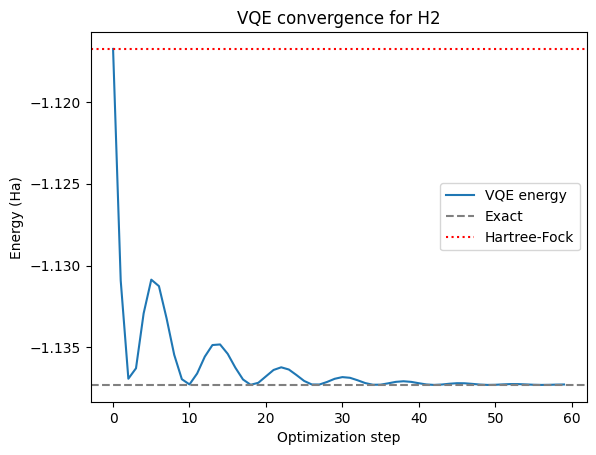

In [3]:
import matplotlib.pyplot as plt

electrons = 2

# Starting point: Hartree-Fock state (the classical mean-field approximation)
hf = qml.qchem.hf_state(electrons, n_qubits)
singles, doubles = qml.qchem.excitations(electrons, n_qubits)
print("HF state:", hf)
print("Single excitations:", singles)
print("Double excitations:", doubles)

dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev)
def circuit(params):
    qml.AllSinglesDoubles(params, wires=range(n_qubits),
                          hf_state=hf, singles=singles, doubles=doubles)
    return qml.expval(H)

n_params = len(singles) + len(doubles)
params = np.zeros(n_params, requires_grad=True)

# Energy at the starting point = Hartree-Fock energy
hf_energy = float(circuit(params))
print(f"\nHartree-Fock energy: {hf_energy:.6f} Ha")

# ---- VQE optimization ----
opt = qml.AdamOptimizer(0.1)
energies = []
for step in range(60):
    params, e = opt.step_and_cost(circuit, params)
    energies.append(float(e))
    if (step + 1) % 10 == 0:
        print(f"step {step+1:02d}  energy {e:.6f} Ha")

vqe_energy = float(circuit(params))
print(f"\nVQE energy:   {vqe_energy:.6f} Ha")
print(f"Exact energy: {exact_energy:.6f} Ha")
print(f"Error:        {abs(vqe_energy - exact_energy) * 1000:.4f} mHa")
print("Chemical accuracy threshold: 1.6 mHa")

# ---- Convergence plot ----
plt.plot(energies, label="VQE energy")
plt.axhline(exact_energy, color="gray", linestyle="--", label="Exact")
plt.axhline(hf_energy, color="red", linestyle=":", label="Hartree-Fock")
plt.xlabel("Optimization step")
plt.ylabel("Energy (Ha)")
plt.title("VQE convergence for H2")
plt.legend()
plt.savefig("vqe_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

d=0.30 Å  exact -0.601804  HF -0.593828  VQE -0.601803  VQE error 0.0001 mHa
d=0.40 Å  exact -0.914150  HF -0.904361  VQE -0.914149  VQE error 0.0005 mHa
d=0.50 Å  exact -1.055160  HF -1.042996  VQE -1.055158  VQE error 0.0021 mHa
d=0.60 Å  exact -1.116286  HF -1.101128  VQE -1.116284  VQE error 0.0019 mHa
d=0.70 Å  exact -1.136189  HF -1.117349  VQE -1.136188  VQE error 0.0010 mHa
d=0.74 Å  exact -1.137284  HF -1.116759  VQE -1.137282  VQE error 0.0016 mHa
d=0.80 Å  exact -1.134148  HF -1.110850  VQE -1.134147  VQE error 0.0008 mHa
d=0.90 Å  exact -1.120560  HF -1.091914  VQE -1.120558  VQE error 0.0019 mHa
d=1.00 Å  exact -1.101150  HF -1.066109  VQE -1.101145  VQE error 0.0049 mHa
d=1.20 Å  exact -1.056741  HF -1.005107  VQE -1.056740  VQE error 0.0005 mHa
d=1.50 Å  exact -0.998149  HF -0.910874  VQE -0.998138  VQE error 0.0110 mHa
d=1.80 Å  exact -0.961817  HF -0.828848  VQE -0.961799  VQE error 0.0183 mHa
d=2.10 Å  exact -0.944375  HF -0.764178  VQE -0.944356  VQE error 0.0188 mHa

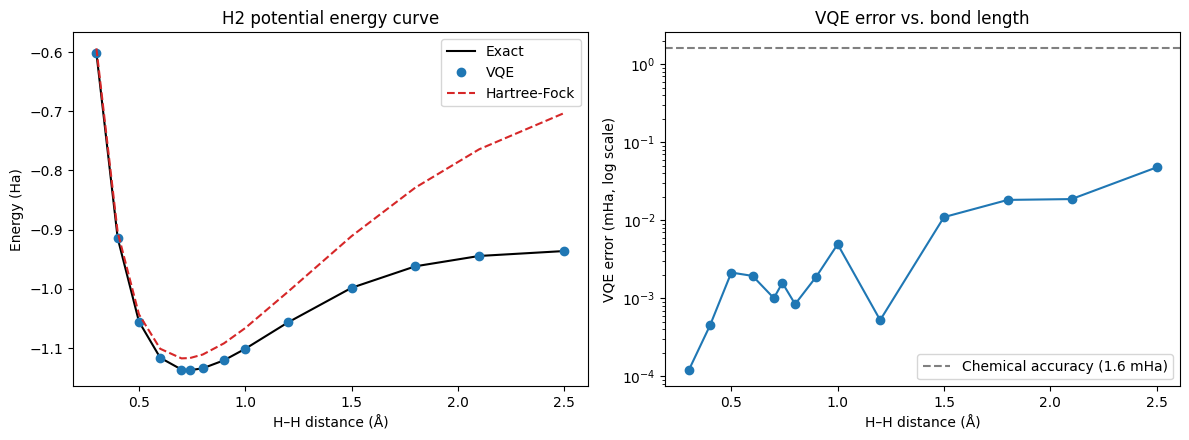

In [4]:
import matplotlib.pyplot as plt

ANG_TO_BOHR = 1.8897259886
bond_lengths = [0.3, 0.4, 0.5, 0.6, 0.7, 0.74, 0.8, 0.9, 1.0, 1.2, 1.5, 1.8, 2.1, 2.5]
electrons = 2

def run_vqe_at(d_angstrom, steps=80, lr=0.1):
    d = d_angstrom * ANG_TO_BOHR
    coords = np.array([0.0, 0.0, -d / 2, 0.0, 0.0, d / 2], requires_grad=False)
    H, nq = qml.qchem.molecular_hamiltonian(["H", "H"], coords)

    exact = onp.linalg.eigvalsh(qml.matrix(H, wire_order=range(nq))).min()

    hf = qml.qchem.hf_state(electrons, nq)
    singles, doubles = qml.qchem.excitations(electrons, nq)
    dev = qml.device("default.qubit", wires=nq)

    @qml.qnode(dev)
    def circ(p):
        qml.AllSinglesDoubles(p, wires=range(nq), hf_state=hf,
                              singles=singles, doubles=doubles)
        return qml.expval(H)

    p = np.zeros(len(singles) + len(doubles), requires_grad=True)
    hf_e = float(circ(p))
    opt = qml.AdamOptimizer(lr)
    for _ in range(steps):
        p = opt.step(circ, p)
    return exact, hf_e, float(circ(p))

exact_list, hf_list, vqe_list = [], [], []
for d in bond_lengths:
    ex, hf_e, vq = run_vqe_at(d)
    exact_list.append(ex); hf_list.append(hf_e); vqe_list.append(vq)
    print(f"d={d:.2f} Å  exact {ex:.6f}  HF {hf_e:.6f}  VQE {vq:.6f}  "
          f"VQE error {abs(vq - ex) * 1000:.4f} mHa")

errors_mha = [abs(v - e) * 1000 for v, e in zip(vqe_list, exact_list)]
i_min = int(onp.argmin(exact_list))
print(f"\nEquilibrium bond length (exact curve minimum): {bond_lengths[i_min]} Å")
print(f"Max VQE error across all distances: {max(errors_mha):.4f} mHa")
print(f"Mean VQE error: {onp.mean(errors_mha):.4f} mHa")

# ---- Plot ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(bond_lengths, exact_list, "k-", label="Exact")
ax[0].plot(bond_lengths, vqe_list, "o", color="tab:blue", label="VQE")
ax[0].plot(bond_lengths, hf_list, "--", color="tab:red", label="Hartree-Fock")
ax[0].set_xlabel("H–H distance (Å)")
ax[0].set_ylabel("Energy (Ha)")
ax[0].set_title("H2 potential energy curve")
ax[0].legend()

ax[1].semilogy(bond_lengths, [max(e, 1e-6) for e in errors_mha], "o-", color="tab:blue")
ax[1].axhline(1.6, color="gray", linestyle="--", label="Chemical accuracy (1.6 mHa)")
ax[1].set_xlabel("H–H distance (Å)")
ax[1].set_ylabel("VQE error (mHa, log scale)")
ax[1].set_title("VQE error vs. bond length")
ax[1].legend()

plt.tight_layout()
plt.savefig("h2_potential_energy_curve.png", dpi=150, bbox_inches="tight")
plt.show()